# LendingClub: кто не вернёт кредит?

**Итоговый проект** по дисциплине *Programming for Data Analysis and Database*, тема №33 «Loan Default Prediction».
Команда: Kilybayev Yersaiyn, Menis Miras, Bekturganov Baknur, AAI-2602M.

### О чём этот проект

LendingClub — американская платформа, где люди брали в долг у других людей. С 2007 по 2018 год через неё выдали
больше двух миллионов займов, и примерно каждый седьмой из них так и не вернули.

Представим, что мы кредитор и к нам пришла заявка. Вопрос простой: **дать деньги или нет?** Чтобы ответить, мы строим
модель, которая по анкете заёмщика оценивает **вероятность дефолта** — шанс, что он не вернёт долг (сокращённо PD,
*probability of default*). Попутно проверяем, насколько хорошо риск оценивает сам LendingClub: он ставит каждому
заёмщику грейд от A (надёжный) до G (рискованный).

Главное правило проекта: модель видит **только то, что известно в момент заявки**. Использовать то, что стало известно
потом (например, сколько заёмщик уже выплатил), — всё равно что подсмотреть ответ.

### Данные

[All Lending Club loan data](https://www.kaggle.com/datasets/wordsforthewise/lending-club), файл
`accepted_2007_to_2018Q4.csv.gz`: **2,26 млн займов, 151 колонка, 374 МБ** в сжатом виде.

### Как читать этот ноутбук

Ноутбук идёт по шагам, как настоящий проект: от сырого файла до готовой модели. Сам конвейер (чтение данных, база,
обучение) лежит в модулях папки `src/` — задание требует разделять код на файлы. Здесь мы вызываем эти функции,
показываем код самых важных из них и разбираем результаты на графиках.

| Раздел | О чём |
|---|---|
| 1. Данные | как прочитать 2,26 млн строк и не переполнить память |
| 2. Аудит качества | какие в данных пропуски и ошибки; нет ли подсказок из будущего |
| 3. Что предсказываем | что считаем дефолтом, почему не все займы годятся, как делим данные по времени |
| 4. База данных и SQL | те же данные в SQLite и 10 аналитических запросов |
| 5. Разведочный анализ | 14 графиков: от чего зависит дефолт |
| 6. Модели | 9 моделей и правило, по которому выбираем лучшую |
| 7. Разбор результатов | насколько модель хороша и как ей пользоваться |
| 8. Проверка смещения | почему незавершённые займы обманывают |
| 9. Одна заявка | модель в действии |
| 10. Скорость и память | CSV против Parquet, Pandas против SQLite |
| 11. Требования задания | где выполнен каждый пункт |

**Запуск.** С файлом Kaggle в папке `datasets/` ноутбук пересчитывает всё на полных данных (около 30 минут).
Без него он сам переходит на демо-выборку из репозитория — 50 тысяч займов, 2–3 минуты. Числа на выборке будут
другими: все пояснения в тексте относятся к полному набору. Результаты ноутбука пишутся в отдельную папку и не
затирают опубликованные отчёты в `reports/`.

In [1]:
# Только для Google Colab: снимите комментарии, чтобы скачать проект и установить библиотеки.
# !git clone https://github.com/yersaa/Loan_default_prediction.git
# %cd Loan_default_prediction
# !pip install -q -r requirements.txt

## 0. Подготовка

Подключаем библиотеки и решаем, на каких данных работать. Все пути и списки колонок проекта собраны в одном месте —
`src/config.py`; в коде он доступен под коротким именем `C`.

Функция `show_source` выводит код любой функции из `src/` прямо сюда, чтобы не переключаться между файлами.

In [2]:
import inspect
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display

from src import config as C
from src.data_io import csv_to_parquet, load_dataset, load_json, mb, memory_report
from src.style import AQUA, BLUE, MUTED, ORANGE, RED, VIOLET, YELLOW

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", message="IProgress not found")  # SHAP ищет виджет прогресса, он не нужен

FULL = C.RAW_CSV.exists() or C.PARQUET.exists()  # есть ли полные данные Kaggle
if FULL:
    C.redirect_outputs(C.NOTEBOOK_RUN)  # результаты ноутбука — в notebook_run/
else:
    C.activate_sample()  # демо-выборка, результаты — в sample_run/
for folder in (C.REPORTS, C.FIGURES, C.MODELS):
    folder.mkdir(parents=True, exist_ok=True)


def show_source(function) -> None:
    """Показывает исходный код функции из src/ блоком кода (читается и в светлой, и в тёмной теме)."""
    display(Markdown(f"```python\n{inspect.getsource(function)}```"))


print("Режим:", "полные данные" if FULL else "демо-выборка")
print("Результаты ноутбука:", C.REPORTS.relative_to(C.ROOT))

Режим: полные данные
Результаты ноутбука: notebook_run\reports


## 1. Данные: как прочитать 2,26 млн строк

Если загрузить исходный CSV целиком, он займёт в памяти около **3 ГБ** — на обычном ноутбуке это много. Поэтому мы
читаем его **по частям** и сразу сохраняем в удобный формат. Этим занимается `csv_to_parquet`:

1. читает файл кусками по 250 тысяч строк (`chunksize`) и только нужные колонки (`usecols`) — из 151 нам нужно 49;
2. каждый кусок чистит: убирает служебные строки-итоги, превращает даты в даты, числа в числа;
3. дописывает куски в один файл **Parquet**.

Parquet — колоночный формат. Он хранит типы данных, хорошо сжимает и умеет читать только нужные колонки, не
трогая остальные. Дальше весь проект работает с ним, а не с CSV.

In [3]:
show_source(csv_to_parquet)

```python
def csv_to_parquet(src: Path | None = None, dst: Path | None = None, chunksize: int | None = None) -> dict:
    """Читает CSV.gz чанками только с нужными колонками и пишет в один Parquet-файл.

    Пишет во временный файл и заменяет им результат только после успеха: прерванная
    конвертация не оставляет усечённый, но читаемый Parquet вместо прежнего.
    """
    src, dst = src or C.RAW_CSV, dst or C.PARQUET
    if not src.exists():
        raise FileNotFoundError(f"Нет файла {src}. Скачайте его с Kaggle (см. README).")
    dst.parent.mkdir(parents=True, exist_ok=True)
    tmp = dst.with_name(dst.name + ".tmp")
    start, rows_raw, rows, schema = time.time(), 0, 0, None
    writer = None
    try:
        try:
            reader = pd.read_csv(src, usecols=C.USECOLS, dtype={"id": str}, chunksize=chunksize or C.CHUNKSIZE,
                                 low_memory=False)
            for i, chunk in enumerate(reader, 1):
                rows_raw += len(chunk)
                chunk = clean_chunk(chunk)[C.USECOLS]
                table = pa.Table.from_pandas(chunk, preserve_index=False)
                if writer is None:
                    schema = table.schema
                    writer = pq.ParquetWriter(tmp, schema, compression="snappy")
                writer.write_table(table.cast(schema))
                rows += len(chunk)
                print(f"  чанк {i}: всего {rows:,} строк")
        except (EOFError, gzip.BadGzipFile, zlib.error) as e:
            raise ValueError(f"Файл {src} повреждён или скачан не полностью: {e}") from e
        finally:
            if writer is not None:
                writer.close()
        if writer is None:
            raise ValueError(f"В файле {src} нет строк с данными.")
        tmp.replace(dst)
    finally:
        tmp.unlink(missing_ok=True)
    stats = {"rows_raw": rows_raw, "rows": rows, "seconds": round(time.time() - start, 1),
             "csv_gz_mb": round(src.stat().st_size / 2**20, 1),
             "parquet_mb": round(dst.stat().st_size / 2**20, 1)}
    save_json(stats, C.REPORTS / "ingest.json")
    print(f"Готово: {stats}")
    return stats
```

Обратите внимание на временный файл `.tmp`: новый Parquet заменяет старый, только когда записаны все куски.
Если чтение оборвётся на середине, рабочий файл не испортится.

In [4]:
if C.RAW_CSV.exists():
    ingest = csv_to_parquet()
else:
    print("Исходного CSV нет, используется готовый файл:", C.PARQUET.relative_to(C.ROOT))

  чанк 1: всего 250,000 строк


  чанк 2: всего 499,998 строк


  чанк 3: всего 749,992 строк


  чанк 4: всего 999,988 строк


  чанк 5: всего 1,249,986 строк


  чанк 6: всего 1,499,982 строк


  чанк 7: всего 1,749,977 строк


  чанк 8: всего 1,999,973 строк


  чанк 9: всего 2,249,969 строк


  чанк 10: всего 2,260,668 строк
Готово: {'rows_raw': 2260701, 'rows': 2260668, 'seconds': 32.9, 'csv_gz_mb': 374.4, 'parquet_mb': 123.1}


In [5]:
df = load_dataset()  # Parquet -> DataFrame, сразу с оптимизированными типами
print(f"Займов: {len(df):,}   колонок: {df.shape[1]}   в памяти: {mb(df)} МБ")
df.head(3)

Займов: 2,260,668   колонок: 49   в памяти: 385.9 МБ


,id,issue_d,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,acc_open_past_24mths,num_tl_op_past_12m,mo_sin_rcnt_tl,mo_sin_old_rev_tl_op,mo_sin_old_il_acct,mths_since_recent_bc,mths_since_recent_inq,mths_since_last_delinq,mths_since_last_record,total_bc_limit,bc_open_to_buy,bc_util,percent_bc_gt_75,total_rev_hi_lim,avg_cur_bal,total_bal_ex_mort,loan_status,total_pymnt,recoveries,last_pymnt_d
0,68407277,2015-12-01,3600.0,36 months,13.99,123.029999,C,C4,10+ years,MORTGAGE,55000.0,Not Verified,debt_consolidation,PA,5.910000,0.0,2003-08-01,675.0,679.0,1.0,7.0,0.0,2765.0,29.700001,13.0,w,Individual,1.0,0.0,4.0,3.0,3.0,128.0,148.0,4.0,4.0,30.0,NaN,2400.0,1506.0,37.200001,0.0,9300.0,20701.0,7746.0,Fully Paid,4421.724121,0.0,2019-01-01
1,68355089,2015-12-01,24700.0,36 months,11.99,820.280029,C,C1,10+ years,MORTGAGE,65000.0,Not Verified,small_business,SD,16.059999,1.0,1999-12-01,715.0,719.0,4.0,22.0,0.0,21470.0,19.200001,38.0,w,Individual,4.0,0.0,4.0,2.0,2.0,192.0,113.0,2.0,0.0,6.0,NaN,79300.0,57830.0,27.100000,7.7,111800.0,9733.0,39475.0,Fully Paid,25679.660156,0.0,2016-06-01
2,68341763,2015-12-01,20000.0,60 months,10.78,432.660004,B,B4,10+ years,MORTGAGE,63000.0,Not Verified,home_improvement,IL,10.780000,0.0,2000-08-01,695.0,699.0,0.0,6.0,0.0,7869.0,56.200001,18.0,w,Joint App,5.0,0.0,6.0,0.0,14.0,184.0,125.0,101.0,10.0,NaN,NaN,6200.0,2737.0,55.900002,50.0,14000.0,31617.0,18696.0,Fully Paid,22705.923828,0.0,2017-06-01


**Почему таблица занимает так мало.** Помогают два приёма (`optimize_dtypes`):

- текстовые колонки с небольшим числом вариантов (грейд, цель займа, штат) хранятся как `category`: каждое значение
  записано один раз, а в строках стоят короткие номера;
- числа хранятся в `float32` вместо `float64` — вдвое меньше места при достаточной точности.

Насколько это помогает, показывает `memory_report`: он сравнивает три варианта загрузки.

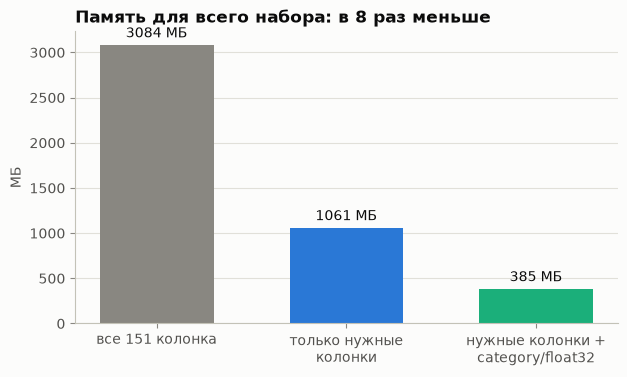

In [6]:
if C.RAW_CSV.exists():
    memory = memory_report()["full_dataset_estimate_mb"]
else:
    memory = load_json(C.ROOT / "reports" / "benchmarks.json")["memory"]["full_dataset_estimate_mb"]

labels = ["все 151 колонка", "только нужные\nколонки", "нужные колонки +\ncategory/float32"]
values = [memory["all_cols"], memory["selected_cols"], memory["selected_optimized"]]
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(labels, values, color=[MUTED, BLUE, AQUA], width=0.6)
ax.bar_label(bars, fmt="%d МБ", padding=3)
ax.set(title=f"Память для всего набора: в {values[0] / values[2]:.0f} раз меньше", ylabel="МБ")
ax.grid(axis="x", visible=False)
plt.show()

**Вывод:** выбор нужных колонок и компактных типов уменьшает объём примерно в 8 раз — с 3 ГБ до 385 МБ.
Без этого полный набор просто не поместился бы в память.

## 2. Аудит качества данных

Прежде чем учить модель, проверим, насколько данным можно доверять. `run_audit` ищет пропуски, повторы, явные ошибки
и выбросы. По его итогам мы решили, что исправлять: например, нулевой доход — это ошибка, и он заменяется пропуском
(`clean_values` в `src/features.py`).

Дубликатов id: 0


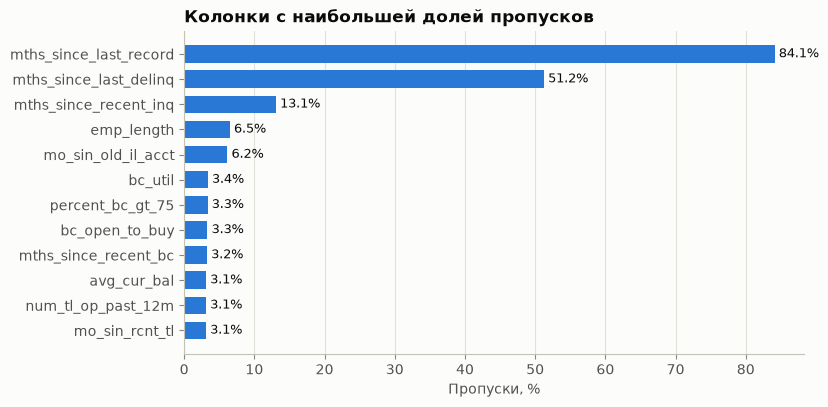

In [7]:
from src.audit import run_audit

audit = run_audit(df)
print("Дубликатов id:", audit["duplicate_ids"])
missing = pd.Series(audit["missing_pct"]).head(12).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(missing.index, missing.values, color=BLUE, height=0.7)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=9)
ax.set(title="Колонки с наибольшей долей пропусков", xlabel="Пропуски, %")
ax.grid(axis="y", visible=False)
plt.show()

**Что видно.** Больше всего пропусков в полях вроде «месяцев с последней просрочки». Это не ошибка: пусто — значит,
просрочек у человека не было. Ещё часть пропусков объясняется тем, что LendingClub начал публиковать данные кредитного
отчёта только в августе 2012 года.

Строки с пропусками мы **не удаляем**: потеряли бы много займов. Модели либо заполняют пропуск типичным значением,
либо, как бустинг, умеют работать с ним сами.

In [8]:
pd.Series(audit["invalid_values"], name="строк с нарушением").to_frame()

,строк с нарушением
annual_inc <= 0,1667
dti < 0 или >= 999,137
revol_util > 150%,28
fico_range_low > fico_range_high,0
earliest_cr_line позже issue_d,0
int_rate вне 5–31%,0


**Проверка «подсказок из будущего».** Признак можно давать модели, только если он был известен в момент заявки.
Для полей кредитного отчёта это не очевидно: вдруг LendingClub обновил их уже после выдачи?

Проверяем хитро: возраст самого старого счёта заёмщика не может быть больше, чем его кредитная история на дату займа.
Если бы поля обновляли в 2018 году, у старых займов такое превышение было бы на годы. Смотрим:

In [9]:
audit['bureau_timing']

{'rows_checked': 2190391, 'max_excess_months': 10.0, 'rows_over_12_months': 0}

**Вывод:** из 2,19 млн займов ни у одного превышение не больше года (максимум — 10 месяцев). Значит, поля сняты
при заявке, и их можно использовать честно.

## 3. Что предсказываем и на каких займах учимся

**Цель.** Займ со статусом `Fully Paid` — погашен (0). `Charged Off` или `Default` — дефолт (1). Остальные статусы,
например `Current`, значат, что заём ещё не закончился, и его исход пока неизвестен.

**Ловушка незавершённых займов.** Возьмём займы на 60 месяцев, выданные в 2015 году. К концу 2018-го большинство из
них ещё выплачивается. Закончились только два вида: те, кто погасил досрочно, и те, кого уже списали. Если просто
выбросить «текущие» займы, среди оставшихся окажется слишком много дефолтов — картина исказится.

Поэтому мы берём только **«созревшие»** займы — те, у которых срок истёк к декабрю 2018 года. Вот как это проверяется:

In [10]:
from src.features import is_matured, modeling_frame, temporal_split

show_source(is_matured)

```python
def is_matured(issue_d: pd.Series, term_months: pd.Series) -> pd.Series:
    """Срок займа истёк к дате выгрузки.

    Незрелые займы отбрасывать только по статусу нельзя: среди ещё не истёкших завершены
    либо досрочно погашенные, либо уже списанные, поэтому дефолтность по ним смещена.
    """
    snapshot = pd.Timestamp(C.SNAPSHOT_YEAR, C.SNAPSHOT_MONTH, 1)
    return months_between(issue_d, snapshot) >= term_months
```

**Делим данные по времени.** Банк учит модель на прошлых займах, а применяет к будущим. Мы делаем так же:
учимся на старых годах, проверяем на более новом. Если бы мы перемешали займы случайно, модель «видела» бы займы того
самого года, на котором её проверяют, и оценка была бы нечестной.

In [11]:
show_source(temporal_split)

```python
def temporal_split(df: pd.DataFrame) -> dict:
    """Окна по году выдачи, без перемешивания.

    fit (2007–2013) и valid (2014) нужны для порога и калибровки,
    train (2007–2014) — для финальной модели, test (2015) — только для оценки.
    """
    year = df["issue_d"].dt.year
    return {"fit": df[year < C.VALID_YEAR], "valid": df[year == C.VALID_YEAR],
            "train": df[year < C.TEST_YEAR], "test": df[year == C.TEST_YEAR]}
```

In [12]:
model_df = modeling_frame(df.copy())  # цель, очистка, новые признаки, только созревшие займы 2007–2015
windows = temporal_split(model_df)

summary = {}
for name, window in windows.items():
    years = sorted(window["issue_d"].dt.year.unique())
    summary[name] = {"годы выдачи": str(years[0]) if len(years) == 1 else f"{years[0]}–{years[-1]}",
                     "займов": len(window), "дефолт, %": round(100 * float(window[C.TARGET].mean()), 2)}
pd.DataFrame(summary).T

,годы выдачи,займов,"дефолт, %"
fit,2007–2013,230706,15.65
valid,2014,162570,13.73
train,2007–2014,393276,14.85
test,2015,283026,14.89


Четыре окна, и у каждого своя роль:

| Окно | Годы | Зачем |
|---|---|---|
| `fit` | 2007–2013 | подбираем настройки моделей |
| `valid` | 2014 | настраиваем вероятности и порог, выбираем лучшую модель |
| `train` | 2007–2014 | учим финальную модель |
| `test` | 2015 | **один раз** проверяем результат — как экзамен, который нельзя пересдать |

**Что видит модель.** 43 признака, известных до выдачи: данные анкеты (доход, стаж, жильё, цель займа), условия
займа (сумма, срок) и 16 полей кредитного отчёта (сколько счетов открыто недавно, насколько загружены кредитки и т. п.).
Проверим, что среди них нет ни одного поля «из будущего»:

In [13]:
print("Признаков:", len(C.FEATURES), "| из них полей кредитного отчёта:", len(C.BUREAU_COLS))
print("Пересечение с полями после выдачи:", set(C.FEATURES) & set(C.LEAKAGE_COLS) or "пусто")
print("Назначает LendingClub, а не заёмщик:", sorted(C.LC_ASSIGNED))

Признаков: 43 | из них полей кредитного отчёта: 16
Пересечение с полями после выдачи: пусто
Назначает LendingClub, а не заёмщик: ['grade', 'initial_list_status', 'installment', 'installment_to_income', 'int_rate', 'sub_grade', 'verification_status']


Пересечение пустое — утечки нет. Последняя строка — поля, которые назначает сам LendingClub: грейд и ставка.
Это не подсказка из будущего, но и не данные заёмщика. Поэтому у нас есть варианты моделей **без** этих полей:
так видно, сколько знает сам LendingClub сверх анкеты.

## 4. База данных SQLite и SQL-запросы

Задание требует положить данные в базу. Мы не складываем всё в одну огромную таблицу, а раскладываем аккуратно
(нормализуем): справочники отдельно, факты отдельно. `build_database` строит такую схему:

- 4 справочника: грейды, цели займа, штаты, типы жилья;
- `loans` — условия займа, `borrowers` — профиль заёмщика, `outcomes` — чем всё закончилось.

Исход займа специально лежит в своей таблице: так его невозможно случайно взять в признаки.

![ER-диаграмма](docs/er_diagram.png)

In [14]:
from src.database import build_database, load_queries, run_all_queries

build_database(df.copy())

  dim_grade             35 строк
  dim_purpose           14 строк
  dim_state             51 строк
  dim_home               6 строк


  loans          2,260,668 строк


  borrowers      2,260,668 строк


  outcomes       2,260,668 строк


{'dim_grade': 35,
 'dim_purpose': 14,
 'dim_state': 51,
 'dim_home': 6,
 'loans': 2260668,
 'borrowers': 2260668,
 'outcomes': 2260668,
 'seconds': 99.6,
 'db_mb': 613.2}

Запросы хранятся в файле `sql/queries.sql`. В них есть всё, что требует задание: объединения таблиц (JOIN),
группировки с условием (GROUP BY и HAVING), подзапросы и CTE, оконные функции `RANK`, `LAG`, `NTILE`, `AVG() OVER`.
Вот, например, запрос, который ранжирует штаты по доле дефолтов — и в целом по стране, и внутри своего региона:

In [15]:
queries = load_queries()
print(len(queries), "запросов:", ", ".join(queries))
print()
print(queries["state_rank"])

10 запросов: default_by_grade, purpose_having, vintage_by_year_term, state_rank, monthly_rolling, yoy_volume_lag, dti_deciles, income_vs_grade_avg, loss_by_grade, fico_home_matrix

-- 4. CTE + оконные RANK(): рейтинг штатов по дефолтности в целом и внутри региона
WITH state_stats AS (
    SELECT s.state_code, s.region,
           COUNT(*)                          AS loans,
           ROUND(AVG(o.is_default) * 100, 2) AS default_rate_pct
    FROM loans l
    JOIN outcomes o  ON o.loan_id = l.loan_id
    JOIN dim_state s ON s.state_code = l.state_code
    WHERE o.is_default IS NOT NULL AND o.is_matured = 1
    GROUP BY s.state_code, s.region
    HAVING COUNT(*) >= 1000
)
SELECT *,
       RANK() OVER (ORDER BY default_rate_pct DESC)                     AS rank_overall,
       RANK() OVER (PARTITION BY region ORDER BY default_rate_pct DESC) AS rank_in_region
FROM state_stats
ORDER BY rank_overall;


In [16]:
sql = run_all_queries()  # словарь {имя запроса: DataFrame}
sql["state_rank"].head(8)

  default_by_grade            7 строк   1.03 c


  purpose_having              8 строк   0.94 c


  vintage_by_year_term       21 строк   3.41 c


  state_rank                 46 строк   1.32 c


  monthly_rolling           103 строк   1.28 c


  yoy_volume_lag             48 строк   4.13 c


  dti_deciles                10 строк   2.75 c


  income_vs_grade_avg        14 строк  18.57 c


  loss_by_grade               7 строк   0.44 c


  fico_home_matrix           12 строк   1.70 c


,state_code,region,loans,default_rate_pct,rank_overall,rank_in_region
0,MS,South,2501,18.79,1,1
1,NV,West,9899,18.08,2,1
2,AR,South,4962,17.82,3,2
3,OK,South,5989,17.57,4,3
4,AL,South,8131,17.34,5,4
5,TN,South,9084,16.80,6,5
6,LA,South,7879,16.61,7,6
7,FL,South,47487,16.42,8,7


Результаты запросов — обычные таблицы Pandas, и дальше мы строим по ним графики. Начнём с грейдов:

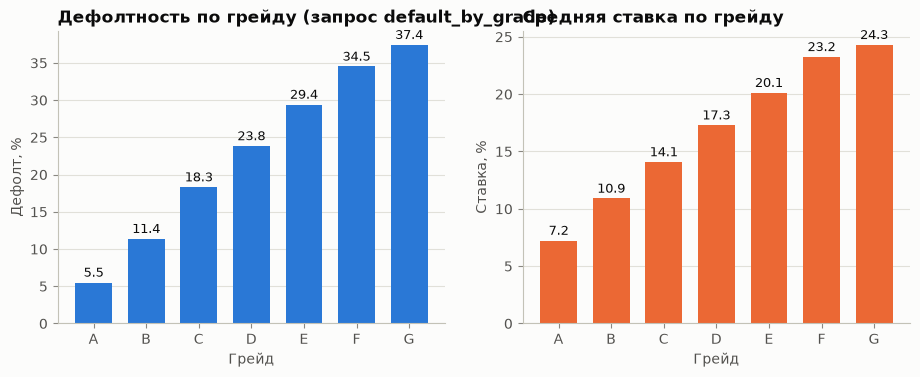

In [17]:
grade = sql["default_by_grade"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.bar(grade["grade"], grade["default_rate_pct"], color=BLUE, width=0.7)
ax1.bar_label(ax1.containers[0], fmt="%.1f", padding=2, fontsize=9)
ax1.set(title="Дефолтность по грейду (запрос default_by_grade)", xlabel="Грейд", ylabel="Дефолт, %")
ax2.bar(grade["grade"], grade["avg_int_rate"], color=ORANGE, width=0.7)
ax2.bar_label(ax2.containers[0], fmt="%.1f", padding=2, fontsize=9)
ax2.set(title="Средняя ставка по грейду", xlabel="Грейд", ylabel="Ставка, %")
for ax in (ax1, ax2):
    ax.grid(axis="x", visible=False)
plt.show()

**Что видно.** Грейды LendingClub работают: чем хуже грейд, тем чаще дефолт — от 5,5% в A до 37% в G. И ставка
растёт вместе с риском: рискованному заёмщику деньги дают дороже.

А вот интересный вопрос: если у двух людей одинаковый грейд, но разный доход, есть ли разница?

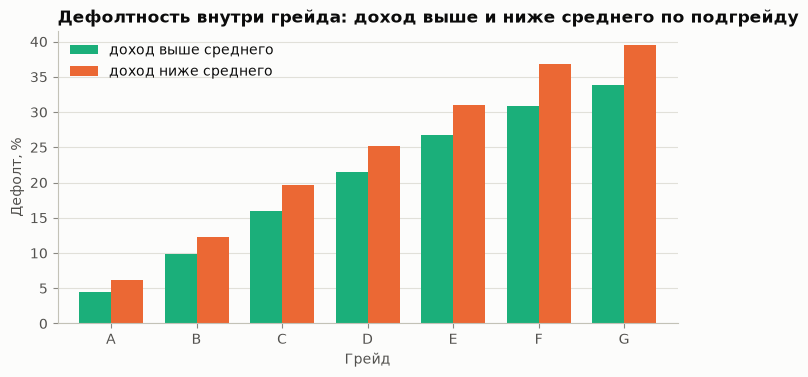

In [18]:
income = sql["income_vs_grade_avg"].pivot(index="grade", columns="income_group", values="default_rate_pct")
ax = income.plot.bar(color=[AQUA, ORANGE], figsize=(8, 3.8), width=0.75, rot=0)
ax.set(title="Дефолтность внутри грейда: доход выше и ниже среднего по подгрейду",
       xlabel="Грейд", ylabel="Дефолт, %")
ax.legend(["доход выше среднего", "доход ниже среднего"])
ax.grid(axis="x", visible=False)
plt.show()

Есть: в каждом грейде люди с доходом ниже среднего дефолтят чаще (в грейде C — 19,7% против 15,9%). Значит, грейд
учитывает не всё, и модели есть что добавить.

## 5. Разведочный анализ: от чего зависит дефолт

Прежде чем строить модель, полезно самим посмотреть на данные. Все доли дефолтов ниже посчитаны по «созревшим» займам.

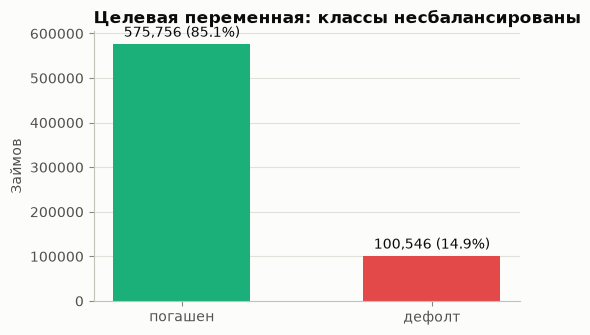

In [19]:
counts = model_df[C.TARGET].map({0: "погашен", 1: "дефолт"}).value_counts()
fig, ax = plt.subplots(figsize=(5.5, 3.5))
bars = ax.bar(counts.index, counts.values, color=[AQUA, RED], width=0.55)
ax.bar_label(bars, labels=[f"{v:,} ({v / counts.sum():.1%})" for v in counts.values], padding=3)
ax.set(title="Целевая переменная: классы несбалансированы", ylabel="Займов")
ax.grid(axis="x", visible=False)
plt.show()

Дефолтов около **15%**. Запомним это — дальше пригодится. Модель, которая всегда отвечает «вернёт», уже права в 85%
случаев, хотя не находит ни одного дефолта. Поэтому долю верных ответов (accuracy) нельзя брать главной оценкой.

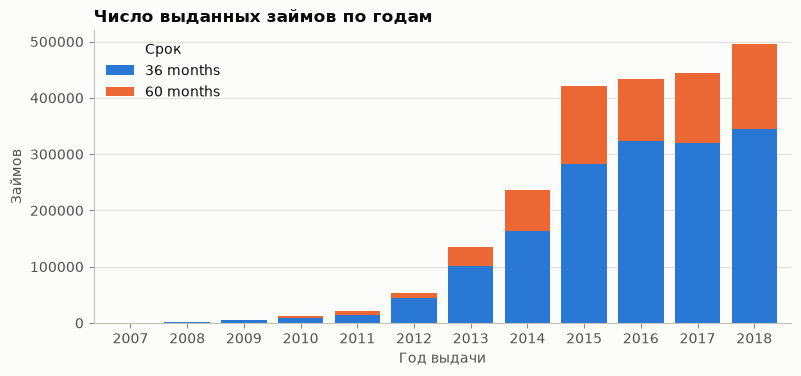

In [20]:
volume = df.groupby([df["issue_d"].dt.year, "term"], observed=True).size().unstack()
ax = volume.plot.bar(stacked=True, color=[BLUE, ORANGE], figsize=(9, 3.8), width=0.8, rot=0)
ax.set(title="Число выданных займов по годам", xlabel="Год выдачи", ylabel="Займов")
ax.legend(title="Срок")
ax.grid(axis="x", visible=False)
plt.show()

Платформа быстро росла: несколько тысяч займов в 2007–2009 годах и сотни тысяч в 2015–2018.

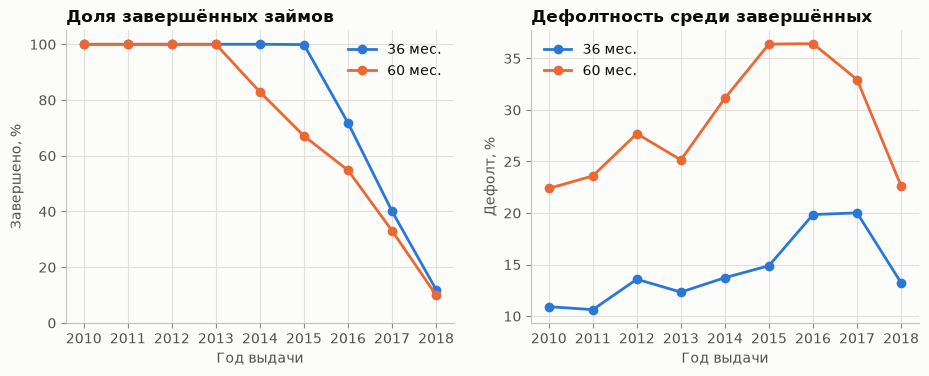

In [21]:
vintage = sql["vintage_by_year_term"]
vintage = vintage[vintage["issue_year"] >= 2010]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for (term, part), color in zip(vintage.groupby("term_months"), [BLUE, ORANGE], strict=False):
    ax1.plot(part["issue_year"], part["resolved_pct"], "o-", color=color, label=f"{term} мес.")
    ax2.plot(part["issue_year"], part["default_rate_pct"], "o-", color=color, label=f"{term} мес.")
ax1.set(title="Доля завершённых займов", xlabel="Год выдачи", ylabel="Завершено, %", ylim=(0, 105))
ax2.set(title="Дефолтность среди завершённых", xlabel="Год выдачи", ylabel="Дефолт, %")
ax1.legend()
ax2.legend()
plt.show()

**Это главный график проекта.** Слева: чем моложе займы, тем меньше их успело закончиться. Справа: среди
закончившихся молодых займов доля дефолтов подскакивает — у 60-месячных займов 2015 года до **36%**, хотя у полностью
созревших займов 2013 года она **25%**. Заёмщики 2015 года не стали вдвое хуже: просто у молодых займов «закончились»
в основном неудачные. Это и есть ловушка из раздела 3, и поэтому мы учимся только на созревших займах.

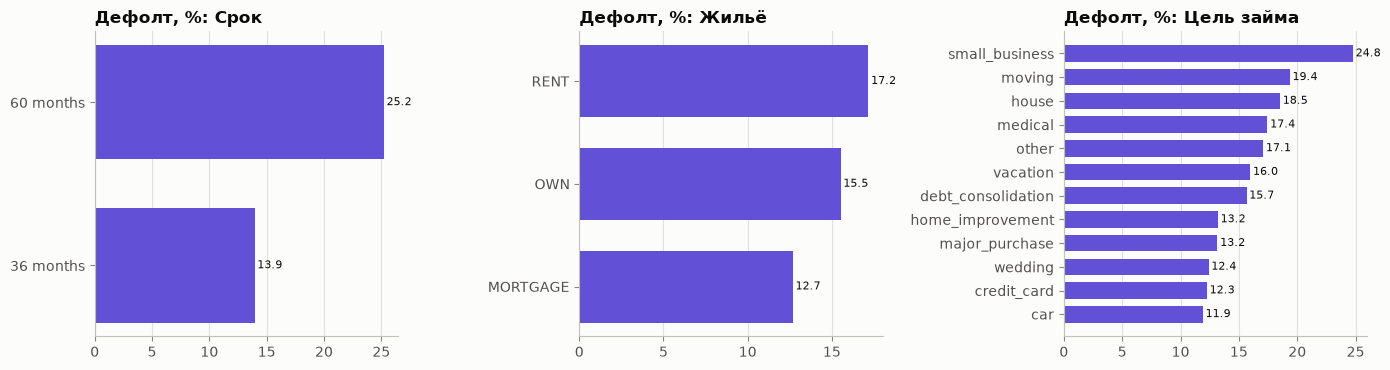

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, column, title in zip(axes, ["term", "home_ownership", "purpose"], ["Срок", "Жильё", "Цель займа"], strict=True):
    rate = model_df.groupby(column, observed=True)[C.TARGET].agg(["mean", "size"])
    rate = rate[rate["size"] >= 2000]["mean"].mul(100).sort_values()
    ax.barh(rate.index.astype(str), rate.values, color=VIOLET, height=0.7)
    ax.bar_label(ax.containers[0], fmt="%.1f", padding=2, fontsize=8)
    ax.set(title=f"Дефолт, %: {title}")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Что видно.**
- Займы на 60 месяцев проваливаются почти вдвое чаще, чем на 36: долгий срок — больше шансов, что что-то пойдёт не так.
- Арендаторы рискованнее, чем владельцы жилья с ипотекой.
- Самая рискованная цель — малый бизнес; самые спокойные — покупка машины и крупные покупки.

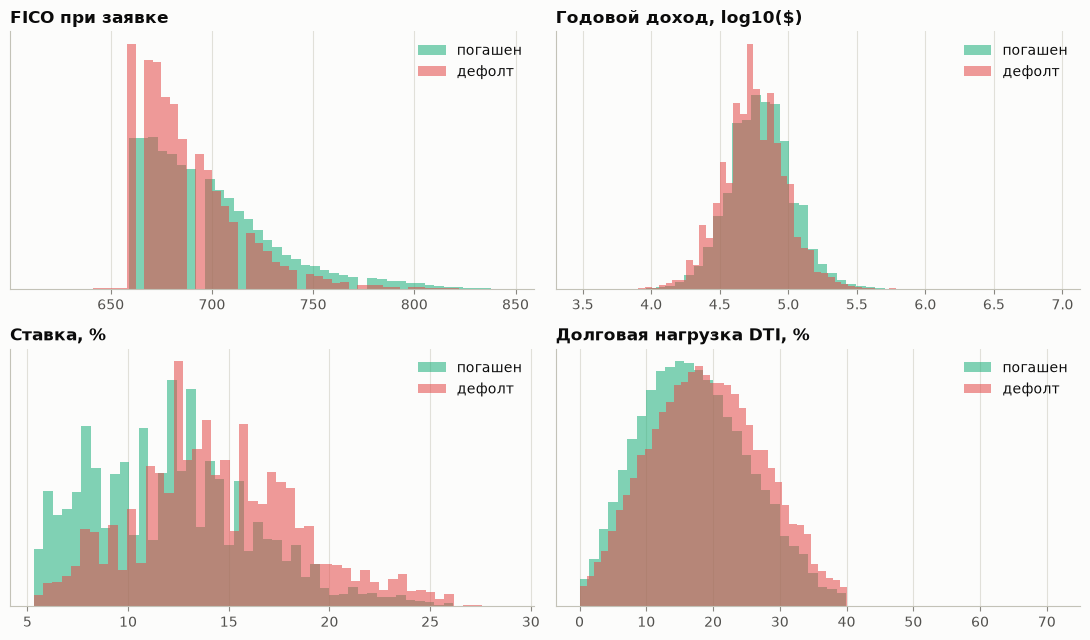

In [23]:
sample = model_df.sample(min(200_000, len(model_df)), random_state=C.RANDOM_STATE)
sample = sample.assign(log_income=np.log10(sample["annual_inc"].clip(lower=1_000)))
panels = [("fico", "FICO при заявке"), ("log_income", "Годовой доход, log10($)"),
          ("int_rate", "Ставка, %"), ("dti", "Долговая нагрузка DTI, %")]
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, (column, title) in zip(axes.ravel(), panels, strict=True):
    for target, color, label in [(0, AQUA, "погашен"), (1, RED, "дефолт")]:
        values = sample.loc[sample[C.TARGET] == target, column].dropna()
        ax.hist(values, bins=50, density=True, alpha=0.55, color=color, label=label)
    ax.set(title=title, yticks=[])
    ax.legend()
plt.tight_layout()
plt.show()

**Как читать.** Зелёное — погашенные займы, красное — дефолтные. Где красного больше, там риск выше.

У тех, кто не вернул долг, в среднем ниже кредитный рейтинг FICO, ниже доход, выше ставка и выше долговая нагрузка
(DTI — какую часть дохода съедают платежи по долгам). Но распределения сильно перекрываются: **ни один признак сам по
себе не отделяет плохих заёмщиков от хороших**. Поэтому и нужна модель, которая учитывает всё сразу.

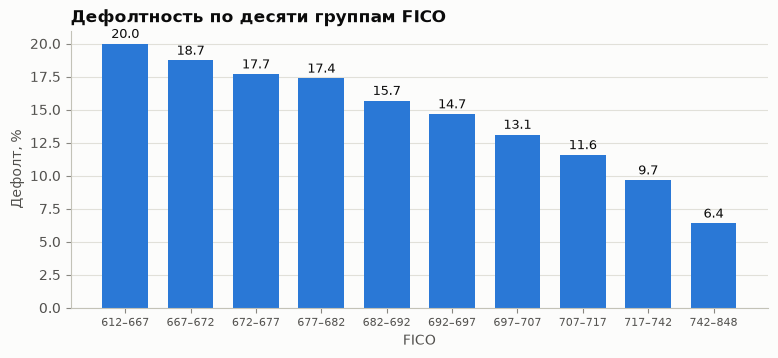

In [24]:
deciles = pd.qcut(model_df["fico"], 10, duplicates="drop")
rate = model_df.groupby(deciles, observed=True)[C.TARGET].mean().mul(100)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar([f"{interval.left:.0f}–{interval.right:.0f}" for interval in rate.index], rate.values, color=BLUE, width=0.7)
ax.bar_label(ax.containers[0], fmt="%.1f", padding=2, fontsize=9)
ax.set(title="Дефолтность по десяти группам FICO", xlabel="FICO", ylabel="Дефолт, %")
ax.tick_params(axis="x", labelsize=8)
ax.grid(axis="x", visible=False)
plt.show()

Чем выше FICO, тем надёжнее заёмщик: от 20% дефолтов в нижней группе до 6% в верхней.

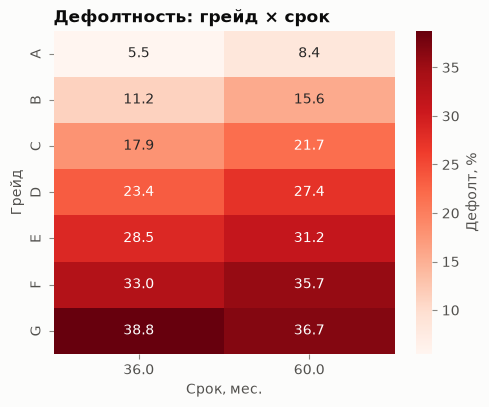

In [25]:
table = model_df.pivot_table(index="grade", columns="term_months", values=C.TARGET, aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(table.mul(100), annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Дефолт, %"}, ax=ax)
ax.set(title="Дефолтность: грейд × срок", xlabel="Срок, мес.", ylabel="Грейд")
plt.show()

При одном и том же грейде заём на 60 месяцев рискованнее, чем на 36. Значит, срок говорит о риске что-то своё,
сверх грейда, и модели полезно видеть оба признака.

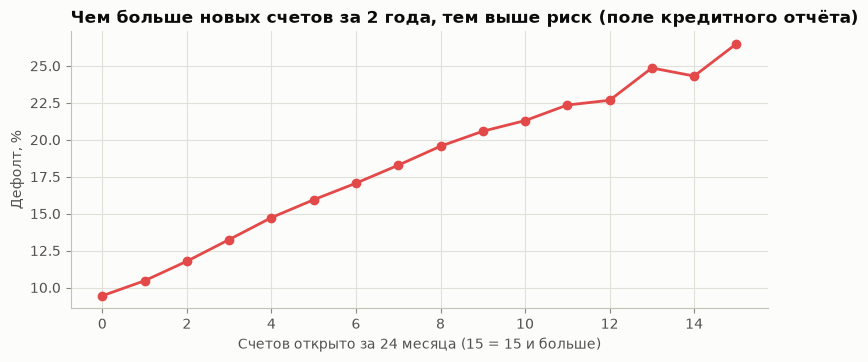

In [26]:
bureau = model_df.dropna(subset=["acc_open_past_24mths"])
opened = bureau["acc_open_past_24mths"].clip(upper=15)
rate = bureau.groupby(opened)[C.TARGET].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(rate.index, rate["mean"] * 100, "o-", color=RED)
ax.set(title="Чем больше новых счетов за 2 года, тем выше риск (поле кредитного отчёта)",
       xlabel="Счетов открыто за 24 месяца (15 = 15 и больше)", ylabel="Дефолт, %")
plt.show()

Поле кредитного отчёта в действии: человек, который за два года открыл много новых кредитов и карт, заметно
рискованнее. Позже мы увидим, что для модели это один из самых важных признаков.

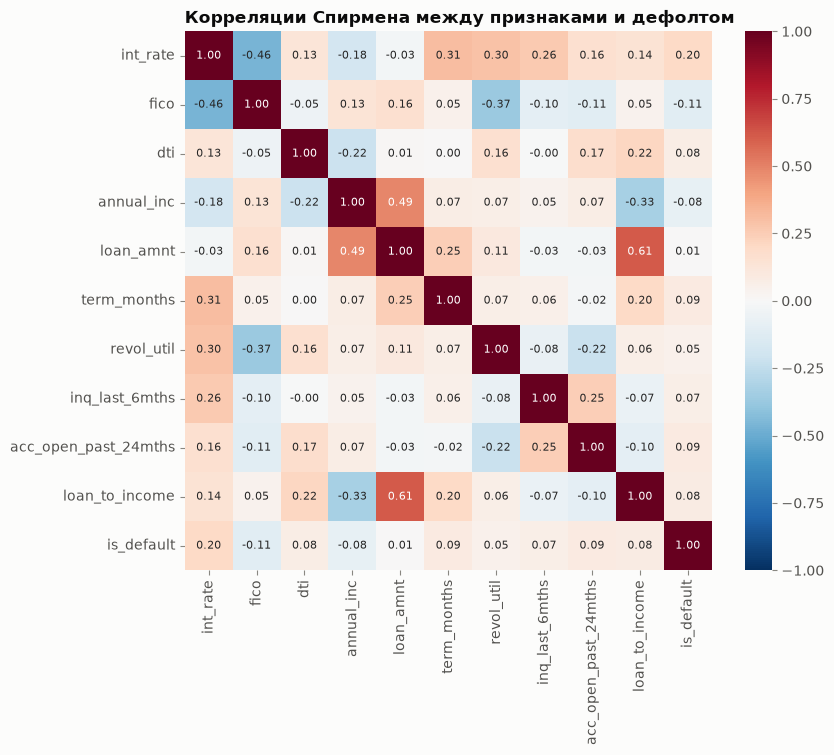

In [27]:
columns = ["int_rate", "fico", "dti", "annual_inc", "loan_amnt", "term_months", "revol_util",
           "inq_last_6mths", "acc_open_past_24mths", "loan_to_income", C.TARGET]
corr = sample[columns].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Корреляции Спирмена между признаками и дефолтом")
plt.show()

**Как читать.** Красное — признаки растут вместе, синее — один растёт, другой падает; число от −1 до 1.

Связь каждого признака с дефолтом по отдельности слабая: сильнее всех ставка (0,20), затем FICO (−0,11). Ещё раз
видим: по одному признаку дефолт не предсказать. Ставка и FICO сильно связаны между собой (−0,46) — ставку и
назначают в том числе по кредитному рейтингу.

## 6. Модели: учим, сравниваем, выбираем

Мы сравниваем девять моделей. Две из них — **точки отсчёта** (baseline): если сложная модель их не обгоняет, она
бесполезна.

| Модель | Что это |
|---|---|
| Dummy | всегда говорит «риск 15%» всем подряд — уровень угадывания |
| Только подгрейд LC | использует одну оценку LendingClub — насколько хорош сам LendingClub |
| Logistic Regression | классическая модель банковского скоринга: простая и понятная |
| LightGBM | градиентный бустинг: много маленьких деревьев решений, каждое исправляет ошибки предыдущих |
| XGBoost | другая реализация бустинга |
| Нейросеть (MLP) | два скрытых слоя по 64 и 32 нейрона |
| Ансамбль | усредняет ответы LightGBM, XGBoost и нейросети |
| LogReg и LightGBM «на полях заёмщика» | то же, но без грейда и ставки от LendingClub |

Сначала подбираем настройки каждой модели (`tune`): перебираем несколько вариантов и смотрим, какой лучше. Проверка
тоже идёт по времени (`TimeSeriesSplit`): модель учится на более ранних годах и проверяется на более поздних.

In [28]:
from src.data_io import save_json
from src.models import train_and_compare, tune

fit = windows["fit"]
best = tune(fit[C.FEATURES], fit[C.TARGET].astype(int))
save_json(best, C.REPORTS / "tuning.json")  # пригодится для замера памяти моделей в разделе 10

  Logistic Regression: {'model__C': 0.05}  CV ROC-AUC=0.6904


  LightGBM: {'model__n_estimators': 300, 'model__num_leaves': 15}  CV ROC-AUC=0.6948


  XGBoost: {'model__max_depth': 4, 'model__n_estimators': 300}  CV ROC-AUC=0.6964


  Neural network (MLP): {'model__alpha': 0.001}  CV ROC-AUC=0.6832


  Logistic Regression (borrower only): {'model__C': 1.0}  CV ROC-AUC=0.6850


  LightGBM (borrower only): {'model__n_estimators': 300, 'model__num_leaves': 15}  CV ROC-AUC=0.6936


Теперь обучаем все модели (`train_and_compare`). Для каждой — два шага:

1. «Пробная» модель учится на 2007–2013 и предсказывает 2014 год. На этом прогнозе мы настраиваем вероятности
   (калибровка Платта) и выбираем порог.
2. Финальная модель учится на 2007–2014 и **один раз** проверяется на 2015 году.

Тест 2015 года ни на что не влияет — только показывает итоговое качество.

In [29]:
metrics, fitted, preds, preds_raw, test = train_and_compare(model_df, best)
y_test = test[C.TARGET].astype(int)
metrics[["model", "valid_auc", "roc_auc", "pr_auc", "ece"]]

  Dummy (prior)                        ROC-AUC=0.5000  fit=0.0c


  Grade only (LogReg)                  ROC-AUC=0.6786  fit=0.5c


  Logistic Regression                  ROC-AUC=0.6950  fit=6.4c


  LightGBM                             ROC-AUC=0.7034  fit=6.4c


  XGBoost                              ROC-AUC=0.7032  fit=7.3c


  Neural network (MLP)                 ROC-AUC=0.6961  fit=11.7c


  Ensemble (LightGBM + XGBoost + MLP)  ROC-AUC=0.7037  fit=24.9c


  Logistic Regression (borrower only)  ROC-AUC=0.6781  fit=4.2c


  LightGBM (borrower only)             ROC-AUC=0.6927  fit=5.3c


,model,valid_auc,roc_auc,pr_auc,ece
0,Dummy (prior),0.5000,0.5000,0.1489,0.0003
1,Grade only (LogReg),0.6595,0.6786,0.2505,0.0202
2,Logistic Regression,0.6804,0.6950,0.2708,0.0106
3,LightGBM,0.6888,0.7034,0.2833,0.0093
4,XGBoost,0.6876,0.7032,0.2831,0.0100
5,Neural network (MLP),0.6787,0.6961,0.2719,0.0057
6,Ensemble (LightGBM + XGBoost + MLP),0.6890,0.7037,0.2829,0.0077
7,Logistic Regression (borrower only),0.6684,0.6781,0.2577,0.0102
8,LightGBM (borrower only),0.6809,0.6927,0.2724,0.0085


### Как понять, хороша ли модель

Модель выдаёт не «да / нет», а **вероятность** дефолта. Поэтому оценок две группы.

**Насколько хороши вероятности** (от порога не зависят):

| Метрика | Что показывает | Как читать |
|---|---|---|
| **ROC-AUC** | умеет ли модель отличать рискованных от надёжных | если взять случайного «плохого» и случайного «хорошего» заёмщика, как часто модель даст плохому больший риск. 0,5 — угадывание, 1 — идеал. **По ней выбираем модель.** |
| **PR-AUC** | как хорошо модель находит именно дефолты | у угадывания равна доле дефолтов, около 0,15 |
| **ECE** | можно ли верить цифре PD | если модель говорит «15%», то среди таких заёмщиков и правда около 15% дефолтов? 0,01 = ошибка в 1 процентный пункт |

**Насколько хороши решения** — когда мы выбрали порог: если PD выше порога, отказываем.

| Метрика | Что показывает |
|---|---|
| **Recall** | какую долю будущих дефолтов мы поймали — остальные станут потерянными деньгами |
| **Precision** | какая доля отказов досталась действительно плохим заёмщикам — остальным мы отказали зря |
| **F1** | баланс precision и recall; по нему выбираем порог |
| **Accuracy** | доля верных решений — показываем только чтобы увидеть, почему ей нельзя верить |

В банках часто говорят про **Gini** — это та же ROC-AUC в другой шкале: Gini = 2 · AUC − 1.

In [30]:
decisions = metrics[["model", "threshold", "accuracy", "precision", "recall", "f1"]].copy()
all_repay = metrics["accuracy_all_repay"].iloc[0]
decisions.loc[len(decisions)] = ["Константа «все вернут»", None, all_repay, None, 0.0, 0.0]
decisions

,model,threshold,accuracy,precision,recall,f1
0,Dummy (prior),0.05,0.1489,0.1489,1.0000,0.2591
1,Grade only (LogReg),0.15,0.6605,0.2366,0.5753,0.3353
2,Logistic Regression,0.16,0.6788,0.2500,0.5789,0.3492
3,LightGBM,0.16,0.6757,0.2524,0.6004,0.3554
4,XGBoost,0.17,0.6975,0.2605,0.5612,0.3558
5,Neural network (MLP),0.15,0.6393,0.2379,0.6458,0.3477
6,Ensemble (LightGBM + XGBoost + MLP),0.16,0.6719,0.2513,0.6083,0.3557
7,Logistic Regression (borrower only),0.15,0.6508,0.2344,0.5937,0.3361
8,LightGBM (borrower only),0.16,0.6757,0.2469,0.5750,0.3455
9,Константа «все вернут»,NaN,0.8511,NaN,0.0000,0.0000


**Почему не accuracy — на примере.** Посмотрите на последнюю строку: «все вернут» получает самую высокую accuracy,
около 0,85, — и при этом не находит **ни одного** дефолта. Наша модель ловит около 60% дефолтов, но часть надёжных
заёмщиков тоже получает отказ, и её accuracy ниже. Если выбирать по accuracy, мы выбрали бы бесполезную модель.
(Dummy при пороге 0,05 отказывает вообще всем — отсюда её странные числа.)

**Как выбираем модель.** Правило записано в коде заранее, до просмотра результатов теста:

1. берём лучшую по ROC-AUC на 2014 годе;
2. если простая логистическая регрессия отстаёт меньше чем на 0,005, берём её — разница в пределах шума, а простота важна;
3. XGBoost, нейросеть или ансамбль заменяют выбор, только если лучше на 0,005 или больше.

In [31]:
from src.models import select_model

show_source(select_model)

```python
def select_model(metrics: pd.DataFrame, specs: list) -> dict:
    """Выбор модели по AUC на валидации (не на test), запас задан в config.SIMPLICITY_MARGIN_AUC.

    Шаг 1. Среди основных моделей берётся лучшая; логистическая регрессия предпочитается,
           если отстаёт меньше чем на запас.
    Шаг 2. Претендент (XGBoost, нейросеть, ансамбль) заменяет выбранную модель, только если лучше её
           на запас или больше: ради прироста в пределах шума модель не меняется.
    """
    by_name = {s.name: s for s in specs}
    scores = metrics.set_index("model")["valid_auc"]
    scores = scores[[name for name in scores.index if name in by_name and not by_name[name].baseline]]
    table = scores[[name for name in scores.index if not by_name[name].challenger]]
    challengers = scores[[name for name in scores.index if by_name[name].challenger]]
    best_name = table.idxmax()
    choice = best_name
    logreg = [n for n in table.index if by_name[n].family == "logreg"
              and ("borrower" in n) == ("borrower" in best_name)]
    if logreg and by_name[best_name].family != "logreg" \
            and table[best_name] - table[logreg[0]] < C.SIMPLICITY_MARGIN_AUC:
        choice = logreg[0]
    if len(challengers) and challengers.max() - scores[choice] >= C.SIMPLICITY_MARGIN_AUC:
        choice = challengers.idxmax()
    margin = C.SIMPLICITY_MARGIN_AUC
    return {"rule": f"max valid_auc (2014); логрегрессия, если отстаёт меньше чем на {margin}; "
                    f"претендент заменяет выбранную модель, только если лучше на {margin} или больше",
            "best_by_valid_auc": best_name, "selected": choice, "valid_auc": table.round(4).to_dict(),
            "challengers_valid_auc": challengers.round(4).to_dict()}
```

In [32]:
selection = load_json(C.REPORTS / "model_selection.json")
chosen = selection["selected"]
print("Выбрана модель:", chosen)
selection

Выбрана модель: LightGBM


{'rule': 'max valid_auc (2014); логрегрессия, если отстаёт меньше чем на 0.005; претендент заменяет выбранную модель, только если лучше на 0.005 или больше',
 'best_by_valid_auc': 'LightGBM',
 'selected': 'LightGBM',
 'valid_auc': {'Logistic Regression': 0.6804,
  'LightGBM': 0.6888,
  'Logistic Regression (borrower only)': 0.6684,
  'LightGBM (borrower only)': 0.6809},
 'challengers_valid_auc': {'XGBoost': 0.6876,
  'Neural network (MLP)': 0.6787,
  'Ensemble (LightGBM + XGBoost + MLP)': 0.689}}

LightGBM обгоняет логистическую регрессию на 0,008 — больше запаса, поэтому выбран он. Ансамбль лучше LightGBM лишь
на 0,0002 — это шум, и менять выбор ради него незачем.

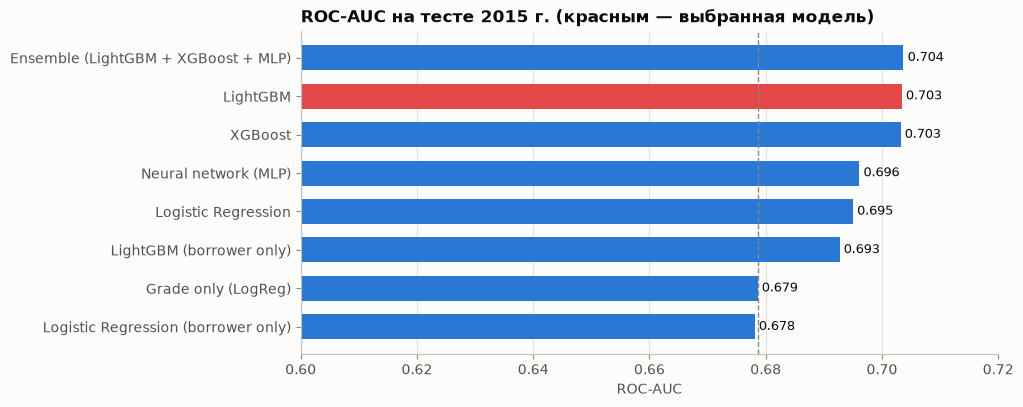

In [33]:
auc = metrics.set_index("model")["roc_auc"].drop("Dummy (prior)").sort_values()
colors = [RED if name == chosen else BLUE for name in auc.index]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(auc.index, auc.values, color=colors, height=0.65)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3, fontsize=9)
ax.axvline(auc["Grade only (LogReg)"], color=MUTED, ls="--", lw=1)
ax.set(title="ROC-AUC на тесте 2015 г. (красным — выбранная модель)", xlim=(0.6, 0.72), xlabel="ROC-AUC")
ax.grid(axis="y", visible=False)
plt.show()

**Итог сравнения.** Все модели обгоняют оценку самого LendingClub (пунктир). Сильные модели сошлись около **0,70**:
LightGBM, XGBoost и ансамбль отличаются в третьем-четвёртом знаке. Это значит, что мы упёрлись в потолок данных:
дело не в алгоритме, а в том, сколько информации о будущем есть в анкете. Для этих данных без подсматривания
0,70 — нормальный результат.

## 7. Разбор результатов

Одной цифры AUC мало. Посмотрим на модель с разных сторон: как она ранжирует, где ошибается, можно ли верить её
вероятностям и как ею пользоваться. Вспомогательные таблицы строит `run_explain`.

In [34]:
from src.explain import run_explain

explained = run_explain(fitted, preds, preds_raw, test, metrics)
main_models = ["Grade only (LogReg)", "Logistic Regression", "LightGBM", "XGBoost", "Neural network (MLP)"]
colors = dict(zip(main_models, [MUTED, BLUE, RED, ORANGE, VIOLET], strict=True))

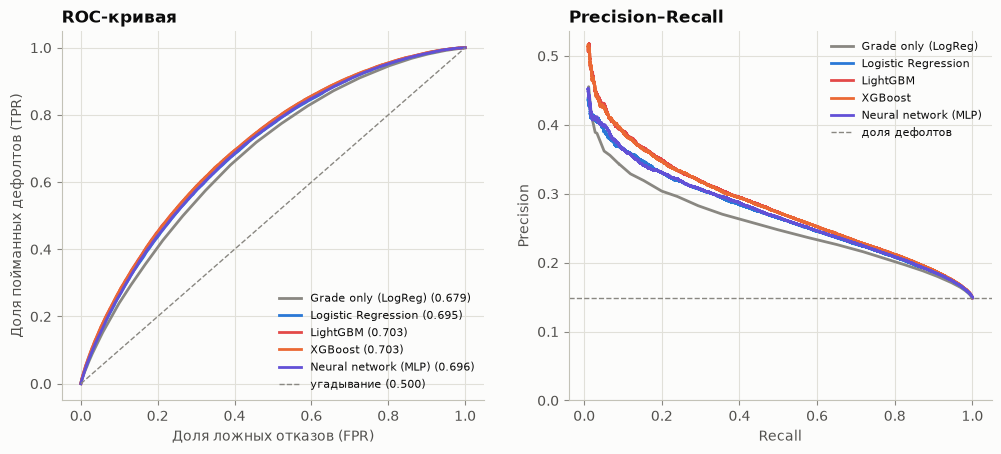

In [35]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
for name in main_models:
    fpr, tpr, _ = roc_curve(y_test, preds[name])
    precision, recall, _ = precision_recall_curve(y_test, preds[name])
    label = f"{name} ({metrics.set_index('model').loc[name, 'roc_auc']:.3f})"
    ax1.plot(fpr, tpr, color=colors[name], label=label)
    keep = recall >= 0.01  # при крошечном recall precision считается по единицам займов
    ax2.plot(recall[keep], precision[keep], color=colors[name], label=name)
ax1.plot([0, 1], [0, 1], "--", color=MUTED, lw=1, label="угадывание (0.500)")
ax2.axhline(y_test.mean(), ls="--", color=MUTED, lw=1, label="доля дефолтов")
ax1.set(title="ROC-кривая", xlabel="Доля ложных отказов (FPR)", ylabel="Доля пойманных дефолтов (TPR)")
ax2.set(title="Precision–Recall", xlabel="Recall", ylabel="Precision", ylim=(0, None))
ax1.legend(fontsize=8)
ax2.legend(fontsize=8)
plt.show()

**ROC-кривая** (слева) показывает сразу все возможные пороги: сколько дефолтов мы поймаем, если готовы отказать
такой-то доле хороших заёмщиков. Чем выше и левее кривая, тем лучше; диагональ — угадывание. Площадь под кривой
и есть ROC-AUC.

**Precision–Recall** (справа): среди самых подозрительных заявок около половины — настоящие дефолты. Но чем больше
дефолтов мы хотим поймать, тем больше зря отказываем хорошим людям.

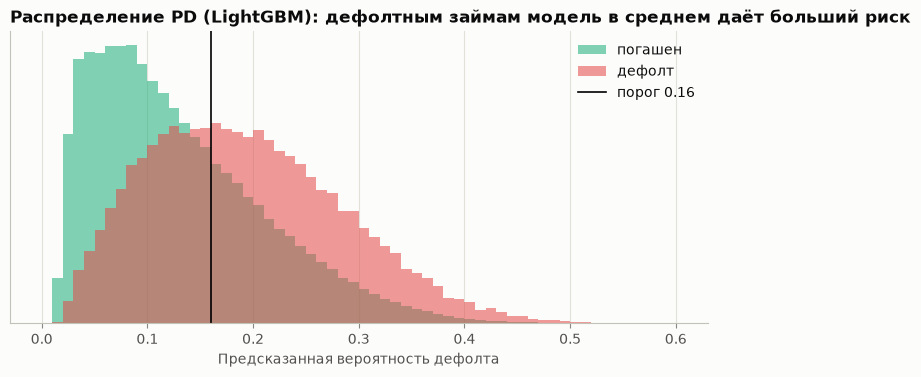

In [36]:
pd_best = preds[chosen]
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0, 0.6, 61)
ax.hist(pd_best[y_test == 0], bins=bins, density=True, alpha=0.55, color=AQUA, label="погашен")
ax.hist(pd_best[y_test == 1], bins=bins, density=True, alpha=0.55, color=RED, label="дефолт")
threshold = metrics.set_index("model").loc[chosen, "threshold"]
ax.axvline(threshold, color="black", lw=1.2, label=f"порог {threshold:.2f}")
ax.set(title=f"Распределение PD ({chosen}): дефолтным займам модель в среднем даёт больший риск",
       xlabel="Предсказанная вероятность дефолта", yticks=[])
ax.legend()
plt.show()

Красное (будущие дефолты) сдвинуто вправо — модель действительно даёт им больший риск. Но зелёное и красное сильно
перекрываются. Поэтому любая граница — компромисс: справа от неё окажутся и плохие, и часть хороших заёмщиков.

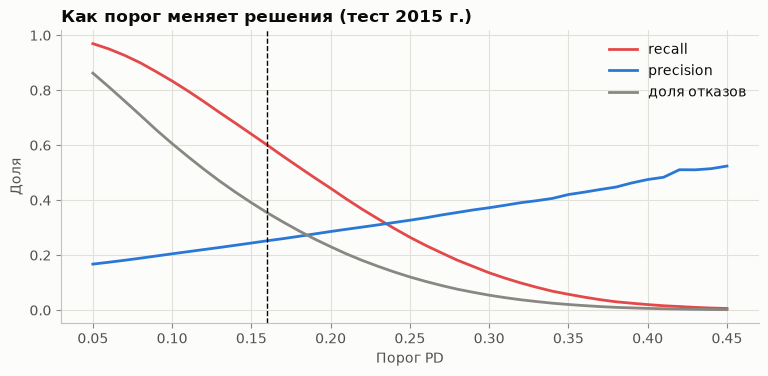

In [37]:
grid = np.linspace(0.05, 0.45, 41)
rows = []
for t in grid:
    refuse = pd_best >= t
    caught = (refuse & (y_test == 1)).sum()
    rows.append({"порог": t, "recall": caught / (y_test == 1).sum(),
                 "precision": caught / max(refuse.sum(), 1), "доля отказов": refuse.mean()})
curve = pd.DataFrame(rows).set_index("порог")
ax = curve.plot(figsize=(9, 3.8), color=[RED, BLUE, MUTED])
ax.axvline(threshold, color="black", lw=1, ls="--")
ax.set(title="Как порог меняет решения (тест 2015 г.)", xlabel="Порог PD", ylabel="Доля")
plt.show()

**Зачем вообще порог.** Модель говорит «риск 18%», а нам нужен ответ «дать или нет». Порог — это граница: выше неё
отказываем. Низкий порог ловит почти все дефолты, но отказывает большинству. Высокий — почти всем одобряет и почти
никого не ловит. Пунктир — наш порог 0,16, выбранный по максимуму F1 на 2014 годе. В реальном банке порог выбирает
бизнес — в зависимости от того, сколько риска он готов принять.

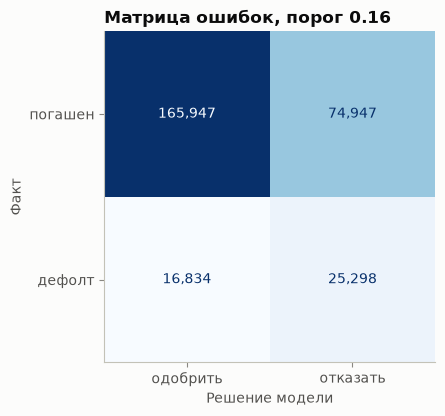

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5, 4.3))
ConfusionMatrixDisplay.from_predictions(y_test, pd_best >= threshold, display_labels=["погашен", "дефолт"],
                                        values_format=",", cmap="Blues", ax=ax, colorbar=False)
ax.set(title=f"Матрица ошибок, порог {threshold:.2f}", xlabel="Решение модели", ylabel="Факт")
ax.set_xticklabels(["одобрить", "отказать"])
ax.grid(False)
plt.show()

**Как читать матрицу.** Строки — что было на самом деле, столбцы — что решила модель. Правый нижний угол — пойманные
дефолты, левый нижний — пропущенные. Правый верхний — хорошие заёмщики, которым мы отказали зря.

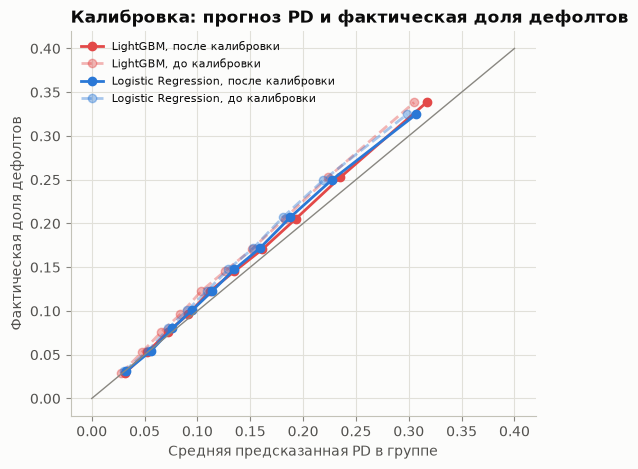

In [39]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6, 5))
for name, color in [(chosen, RED), ("Logistic Regression", BLUE)]:
    fact, forecast = calibration_curve(y_test, preds[name], n_bins=10, strategy="quantile")
    fact_raw, forecast_raw = calibration_curve(y_test, preds_raw[name], n_bins=10, strategy="quantile")
    ax.plot(forecast, fact, "o-", color=color, label=f"{name}, после калибровки")
    ax.plot(forecast_raw, fact_raw, "o--", color=color, alpha=0.4, label=f"{name}, до калибровки")
ax.plot([0, 0.4], [0, 0.4], color=MUTED, lw=1)
ax.set(title="Калибровка: прогноз PD и фактическая доля дефолтов",
       xlabel="Средняя предсказанная PD в группе", ylabel="Фактическая доля дефолтов")
ax.legend(fontsize=8)
plt.show()

**Можно ли верить цифре PD?** Разбиваем займы на 10 групп по прогнозу и сравниваем прогноз с фактом. Если точки на
серой диагонали, модель «говорит правду»: где она обещает 20%, там и есть около 20% дефолтов. Пунктир — до
калибровки, сплошная — после. Калибровка Платта подтягивает точки к диагонали и не меняет порядок заёмщиков, поэтому
ROC-AUC остаётся прежней.

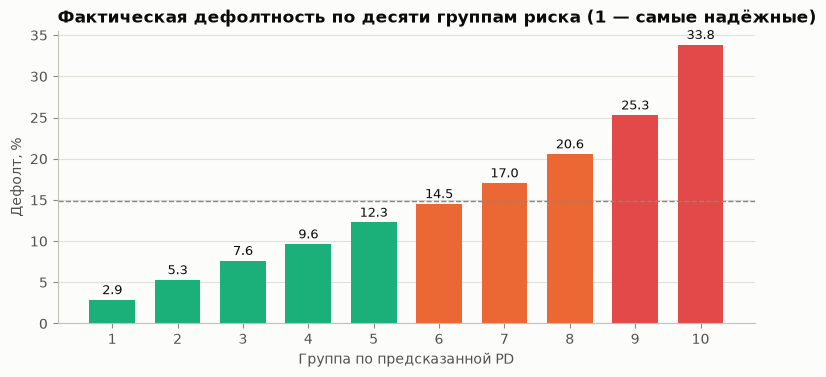

In [40]:
deciles = pd.qcut(pd.Series(pd_best).rank(method="first"), 10, labels=range(1, 11))
lift = pd.DataFrame({"y": y_test.to_numpy(), "decile": deciles.to_numpy()}).groupby("decile", observed=True)["y"].mean()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(lift.index.astype(str), lift.values * 100, color=[AQUA] * 5 + [ORANGE] * 3 + [RED] * 2, width=0.7)
ax.bar_label(ax.containers[0], fmt="%.1f", padding=2, fontsize=9)
ax.axhline(y_test.mean() * 100, color=MUTED, ls="--", lw=1)
ax.set(title="Фактическая дефолтность по десяти группам риска (1 — самые надёжные)",
       xlabel="Группа по предсказанной PD", ylabel="Дефолт, %")
ax.grid(axis="x", visible=False)
plt.show()

**Самый наглядный результат.** Делим всех заёмщиков 2015 года на 10 равных групп по прогнозу модели. В самой надёжной
группе не вернули долг около **3%**, в самой рискованной — около **34%**, при среднем 15% (пунктир). Модель
действительно отделяет надёжных от рискованных — именно это и нужно кредитору.

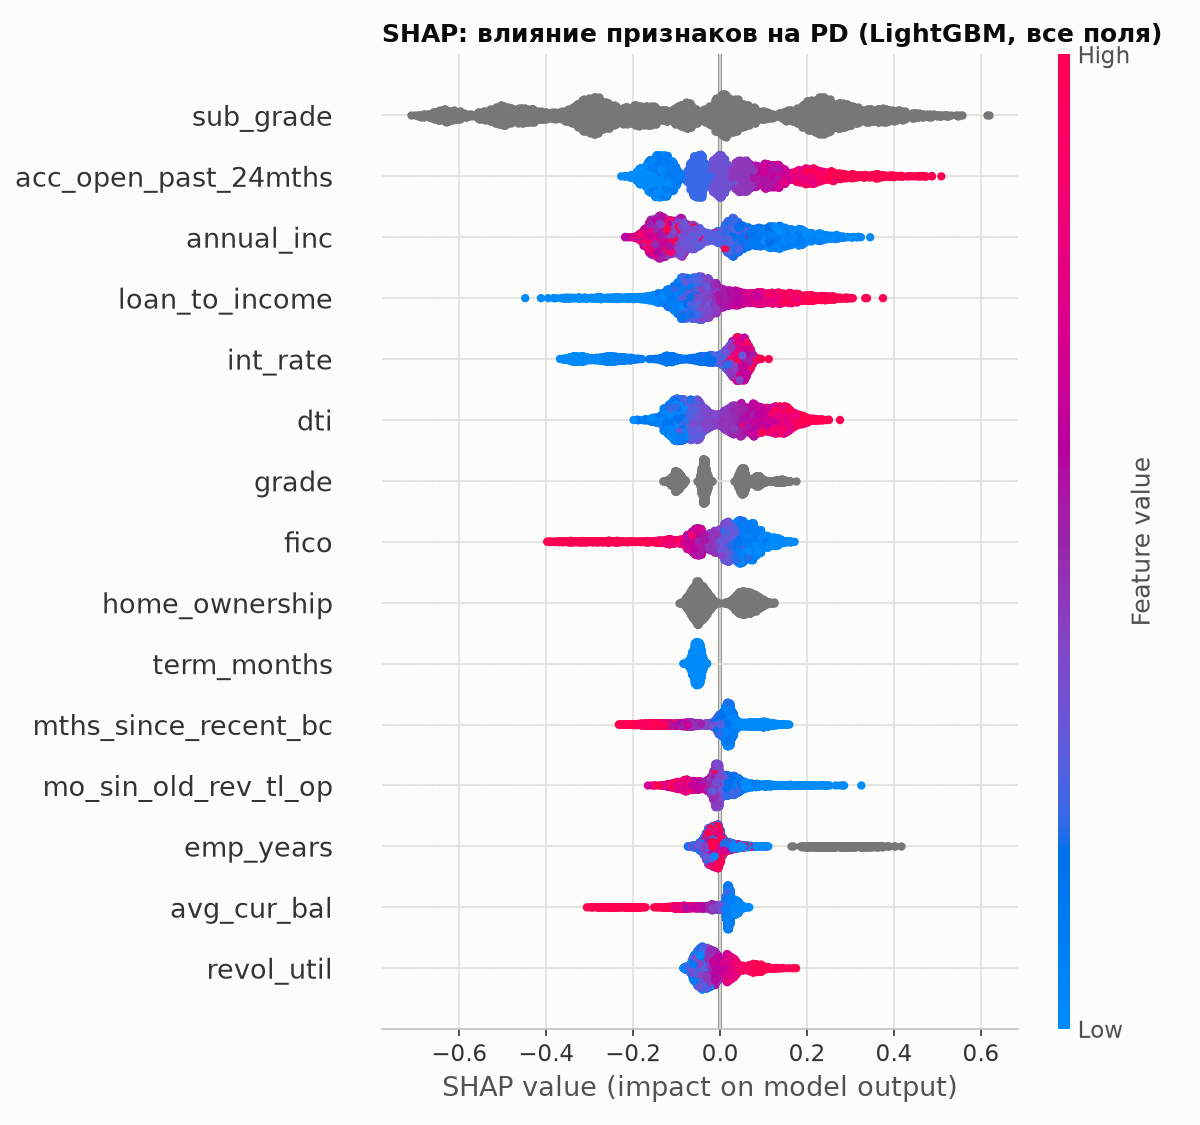

In [41]:
display(Image(filename=str(C.FIGURES / "12_shap_summary.png"), width=650))

**Почему модель так решает (SHAP).** Каждая точка — один заём; положение по горизонтали — насколько этот признак
сдвинул его риск (вправо — к дефолту), цвет — значение признака (красный — большое). Важнее всего подгрейд, число
недавно открытых счетов, доход, отношение суммы займа к доходу, ставка, долговая нагрузка и FICO — ровно то, что мы
видели в разведочном анализе.

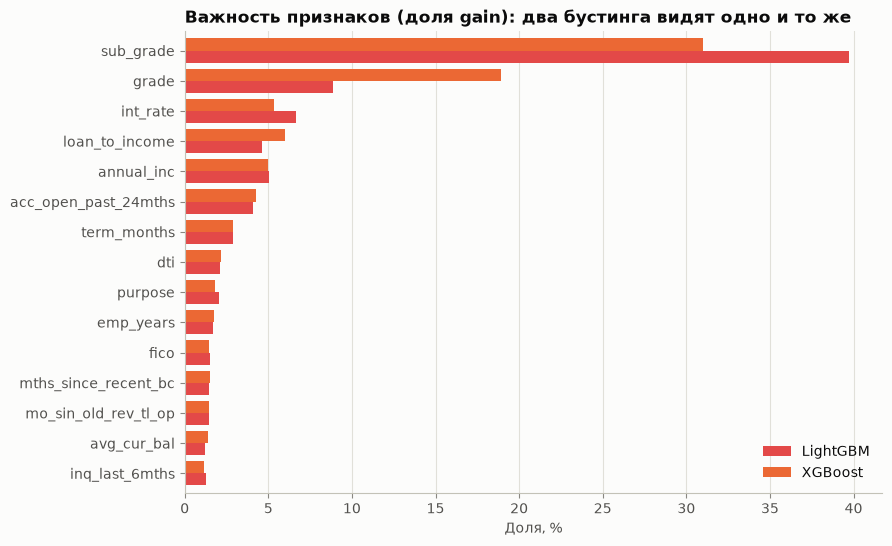

In [42]:
def gain_share(booster_gain: dict) -> pd.Series:
    """Важность признаков как доля суммарного прироста качества (gain) по всем деревьям, %."""
    gain = pd.Series(booster_gain, dtype=float)
    return gain / gain.sum() * 100


lgbm = fitted["LightGBM"].named_steps["model"].booster_
xgb = fitted["XGBoost"].named_steps["model"].get_booster()
importance = pd.DataFrame({
    "LightGBM": gain_share(dict(zip(lgbm.feature_name(), lgbm.feature_importance("gain"), strict=True))),
    "XGBoost": gain_share(xgb.get_score(importance_type="total_gain")),
}).fillna(0)
top = importance.loc[importance.mean(axis=1).nlargest(15).index[::-1]]
ax = top.plot.barh(color=[RED, ORANGE], figsize=(9, 6), width=0.8)
ax.set(title="Важность признаков (доля gain): два бустинга видят одно и то же", xlabel="Доля, %")
ax.grid(axis="y", visible=False)
plt.show()

Два разных алгоритма независимо считают важными одни и те же признаки. Это хороший знак: модели нашли настоящие
закономерности, а не случайный шум.

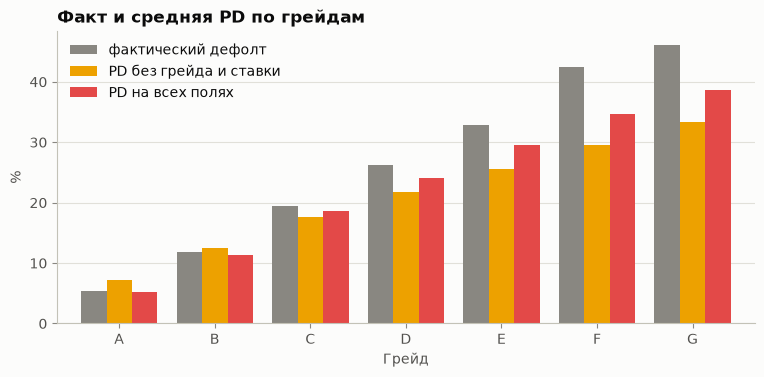

In [43]:
recovery = explained["recovery"].set_index("grade")
ax = recovery[["actual_default_pct", "borrower_pd_pct", "full_pd_pct"]].plot.bar(
    color=[MUTED, YELLOW, RED], figsize=(9, 3.8), width=0.8, rot=0)
ax.set(title="Факт и средняя PD по грейдам", xlabel="Грейд", ylabel="%")
ax.legend(["фактический дефолт", "PD без грейда и ставки", "PD на всех полях"])
ax.grid(axis="x", visible=False)
plt.show()

**Что знает LendingClub сверх анкеты.** Модель без грейда и ставки (жёлтая) по общей оценке уже сильнее одного
грейда: данные кредитного отчёта восстанавливают большую часть того, что знает LendingClub. Но без грейда модель
«сглаживает» риск: самым надёжным (A) приписывает лишнее, самым рискованным (F, G) — недостаёт. Значит, грейд всё же
несёт что-то своё.

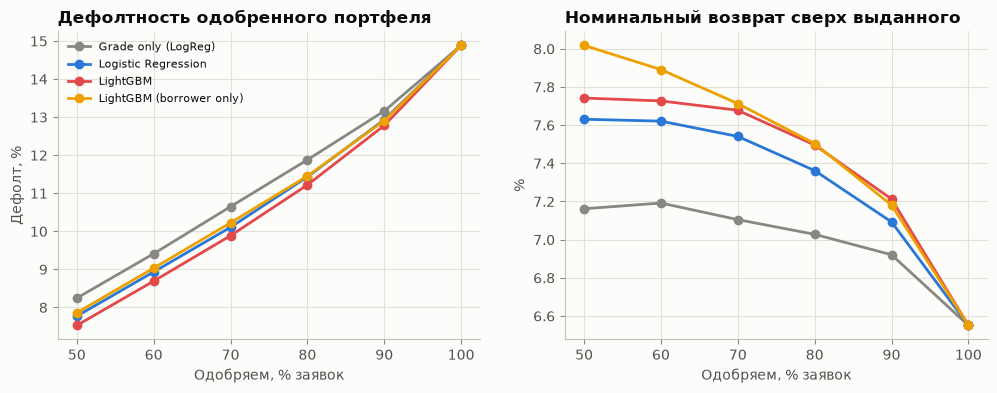

model,Grade only (LogReg),LightGBM,LightGBM (borrower only),Logistic Regression
approval_rate,,,,
0.5,8.2,7.5,7.9,7.8
0.6,9.4,8.7,9.0,8.9
0.7,10.6,9.9,10.2,10.1
0.8,11.9,11.2,11.5,11.4
0.9,13.2,12.8,12.9,12.9
1.0,14.9,14.9,14.9,14.9


In [44]:
approval = explained["approval"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for name, part in approval.groupby("model", sort=False):
    color = {"Grade only (LogReg)": MUTED, "Logistic Regression": BLUE, "LightGBM": RED}.get(name, YELLOW)
    ax1.plot(part["approval_rate"] * 100, part["default_rate_pct"], "o-", color=color, label=name)
    ax2.plot(part["approval_rate"] * 100, part["net_return_pct"], "o-", color=color, label=name)
ax1.set(title="Дефолтность одобренного портфеля", xlabel="Одобряем, % заявок", ylabel="Дефолт, %")
ax2.set(title="Номинальный возврат сверх выданного", xlabel="Одобряем, % заявок", ylabel="%")
ax1.legend(fontsize=8)
plt.show()
approval.pivot(index="approval_rate", columns="model", values="default_rate_pct").round(1)

**Как модель используют на практике.** Банк решает: «одобряем 80% самых надёжных заявок». Модель сортирует заявки по
риску, и дефолтов среди одобренных становится около **11%** вместо 15%, если одобрять всех. Справа — сколько денег
вернулось сверх выданного. Это номинальная цифра за весь срок, без учёта стоимости денег, поэтому она подходит для
сравнения моделей, но не как прогноз прибыли.

## 8. Проверка: насколько обманывают незавершённые займы

В разделе 5 мы увидели ловушку. Теперь измерим её. `censoring_sensitivity` обучает те же модели на «всех
завершённых» займах, не выбрасывая незрелые, и сравнивает с нашим честным вариантом.

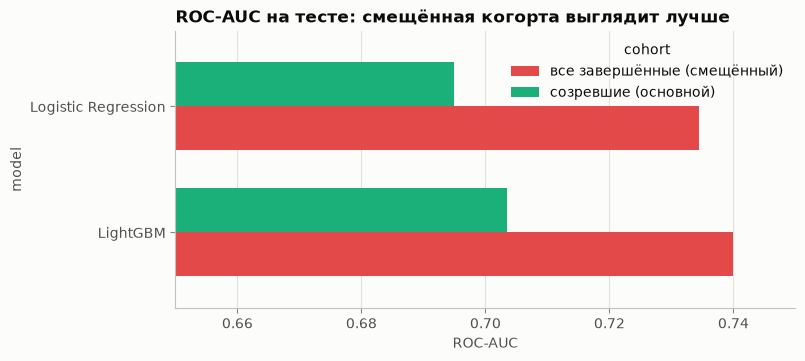

,cohort,model,train_rows,test_rows,train_default_pct,test_default_pct,mean_pd_pct,test_auc,auc_36m,auc_60m
0,созревшие (основной),Logistic Regression,393276,283026,14.85,14.89,13.35,0.6950,0.6950,NaN
1,созревшие (основной),LightGBM,393276,283026,14.85,14.89,13.17,0.7034,0.7034,NaN
2,все завершённые (смещённый),Logistic Regression,453809,375546,17.03,20.19,17.83,0.7345,0.6955,0.6757
3,все завершённые (смещённый),LightGBM,453809,375546,17.03,20.19,17.57,0.7399,0.7036,0.6793


In [45]:
from src.censoring import censoring_sensitivity

censoring = censoring_sensitivity(df, best)
fig, ax = plt.subplots(figsize=(8, 3.6))
pivot = censoring.pivot(index="model", columns="cohort", values="test_auc")
pivot.plot.barh(ax=ax, color=[RED, AQUA], width=0.7)
ax.set(title="ROC-AUC на тесте: смещённая когорта выглядит лучше", xlabel="ROC-AUC", xlim=(0.65, 0.75))
ax.grid(axis="y", visible=False)
plt.show()
censoring

На «всех завершённых» займах AUC выглядит лучше — около 0,74 против 0,70. Но если сравнить только займы на 36 месяцев
(колонка `auc_36m`), результаты почти одинаковы. Значит, «прибавка» — не заслуга модели, а смещение: она научилась
узнавать незрелые 60-месячные займы, среди которых завершились в основном плохие. Мы сознательно берём меньшую,
но честную цифру.

## 9. Модель в действии: одна заявка

Возьмём условного заёмщика: просит 15 тысяч долларов на 3 года, доход 65 тысяч, FICO 700, снимает жильё.
`predict_pd` проверяет анкету, считает признаки тем же кодом, что при обучении, и выдаёт риск и решение каждой модели.
Поля, которых в анкете нет (например, данные кредитного отчёта), заполняются типичными значениями.

In [46]:
from src.models import predict_pd

application = {
    "loan_amnt": 15000, "term_months": 36, "int_rate": 13.0, "sub_grade": "C1", "annual_inc": 65000, "dti": 18,
    "fico": 700, "emp_years": 5, "revol_util": 50, "inq_last_6mths": 1, "credit_hist_months": 180,
    "home_ownership": "RENT", "purpose": "debt_consolidation", "verification_status": "Source Verified",
    "initial_list_status": "w", "application_type": "Individual",
}
pd.DataFrame(predict_pd(application)).T

,pd,threshold,decision
LightGBM,0.135456,0.16,одобрить
Logistic Regression,0.160698,0.16,отказ
LightGBM (borrower only),0.099524,0.16,одобрить


А если в анкете ошибка, программа не падает, а объясняет, что не так (`try` / `except`):

In [47]:
try:
    predict_pd({**application, "fico": 300})
except ValueError as error:
    print("Ошибка:", error)

Ошибка: fico = 300: допустимо от 600 до 850


## 10. Скорость и память: CSV против Parquet, Pandas против SQLite

Задание требует обосновать выбор инструментов цифрами. `run_benchmarks` замеряет время и память. Чтобы замеры были
честными, каждая задача запускается **в отдельном новом процессе** три раза, и берётся среднее (медиана): так одна
задача не влияет на другую через уже занятую память.

In [48]:
if C.RAW_CSV.exists():
    from src.benchmark import run_benchmarks
    bench = run_benchmarks()
else:
    bench = load_json(C.ROOT / "reports" / "benchmarks.json")
print("Результаты Pandas и SQL совпали:", bench["pandas_vs_sql"]["results_match"])

  Dummy (prior)                        память обучения     4.4 МБ


  Grade only (LogReg)                  память обучения    38.6 МБ


  Logistic Regression                  память обучения   664.9 МБ


  LightGBM                             память обучения   235.8 МБ


  XGBoost                              память обучения   309.6 МБ


  Neural network (MLP)                 память обучения   698.6 МБ


  Ensemble (LightGBM + XGBoost + MLP)  память обучения   649.4 МБ


  Logistic Regression (borrower only)  память обучения   346.3 МБ


  LightGBM (borrower only)             память обучения   206.1 МБ
Результаты Pandas и SQL совпали: True


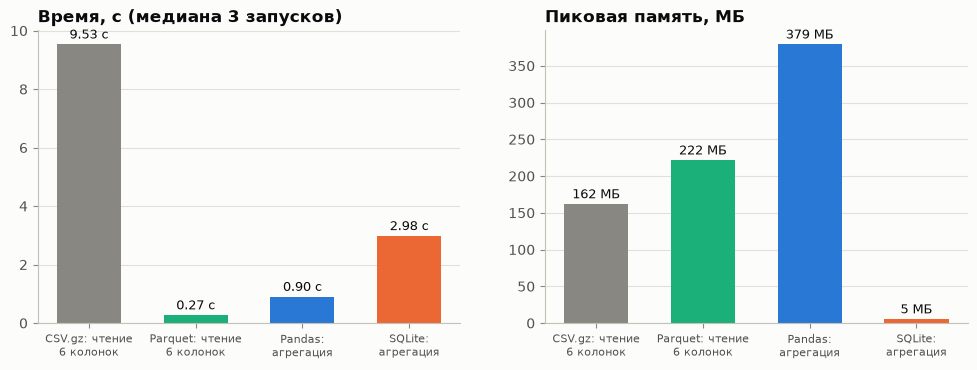

In [49]:
tasks = {"CSV.gz: чтение\n6 колонок": bench["csv_vs_parquet"]["csv_gz"],
         "Parquet: чтение\n6 колонок": bench["csv_vs_parquet"]["parquet"],
         "Pandas:\nагрегация": bench["pandas_vs_sql"]["pandas_parquet"],
         "SQLite:\nагрегация": bench["pandas_vs_sql"]["sqlite"]}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
colors_bench = [MUTED, AQUA, BLUE, ORANGE]
ax1.bar(tasks.keys(), [t["seconds"] for t in tasks.values()], color=colors_bench, width=0.6)
ax1.bar_label(ax1.containers[0], fmt="%.2f с", padding=2, fontsize=9)
ax2.bar(tasks.keys(), [t["peak_mb"] for t in tasks.values()], color=colors_bench, width=0.6)
ax2.bar_label(ax2.containers[0], fmt="%.0f МБ", padding=2, fontsize=9)
ax1.set(title="Время, с (медиана 3 запусков)")
ax2.set(title="Пиковая память, МБ")
for ax in (ax1, ax2):
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", visible=False)
plt.show()

**Что видно.**
- Parquet читает те же колонки в десятки раз быстрее, чем CSV.
- Pandas считает сводку быстрее SQLite, но SQLite почти не тратит память программы: данные остаются на диске.

**Отсюда наш выбор:** Parquet — рабочий формат, Pandas — для анализа и обучения, SQLite — для аккуратного хранения
и запросов, когда памяти мало. И ещё: результаты Pandas и SQL совпали — оба способа считают одно и то же.

In [50]:
cost = metrics[["model", "fit_seconds", "predict_ms_per_1000", "model_mb"]].copy()
cost.insert(2, "fit_peak_mb", cost["model"].map(lambda name: bench["model_fit_memory"][name]["fit_peak_mb"]))
cost.round(2)

,model,fit_seconds,fit_peak_mb,predict_ms_per_1000,model_mb
0,Dummy (prior),0.03,4.4,0.05,0.00
1,Grade only (LogReg),0.55,38.6,0.35,0.00
2,Logistic Regression,6.45,664.9,2.73,0.01
3,LightGBM,6.36,235.8,6.37,0.53
4,XGBoost,7.26,309.6,3.06,0.51
5,Neural network (MLP),11.67,698.6,3.27,0.22
6,Ensemble (LightGBM + XGBoost + MLP),24.89,649.4,12.60,1.26
7,Logistic Regression (borrower only),4.17,346.3,1.71,0.01
8,LightGBM (borrower only),5.29,206.1,6.20,0.52


**Цена качества.** Ансамбль даёт крошечную прибавку, но учится в несколько раз дольше и медленнее отвечает.
LightGBM при том же качестве учится быстро и требует меньше памяти, чем логистическая регрессия и нейросеть.
Это ещё один довод в пользу выбранной модели.

## 11. Соответствие требованиям задания

| № | Требование | Где выполнено |
|---|---|---|
| 1 | Не менее 5 функций | более 120 функций в `src/`, `main.py`, `app.py`; код ключевых показан в разделах 1, 3, 6 |
| 2 | Списки и словари | `MENU`, `STEPS` в `main.py`; словари `sql` и `summary` в этом ноутбуке; реестр моделей |
| 3 | `if` / `elif` / `else` | `menu_loop` в `main.py`, выбор режима в разделе 0 |
| 4 | Циклы | меню и повтор ввода в `main.py`; циклы по моделям и графикам здесь |
| 5 | Работа с файлами | CSV, Parquet, JSON, SQLite, joblib (разделы 1, 4, 6) |
| 6 | `try` / `except` | раздел 9; `run_step`, `load_json`, `csv_to_parquet` |
| 7 | Интерфейс | консольное меню `python main.py`, дашборд `streamlit run app.py` |
| 8 | Модульность | 12 модулей в `src/`; `pathlib`, `json`, `datetime`, `sqlite3`, `argparse` |
| 9 | Сравнение подходов с baseline | 9 моделей против Dummy и «только подгрейд» по качеству, времени и памяти (разделы 6, 10); CSV/Parquet и Pandas/SQL (раздел 10) |
| 10 | SQLite, ER-диаграмма, 8+ запросов | раздел 4: 7 таблиц, 10 запросов с JOIN, HAVING, CTE, подзапросом и оконными функциями |
| 11 | Объём данных | 2,26 млн строк; чтение частями, Parquet, оптимизация типов с замером (раздел 1) |
| Тема 33 | Чтение частями + Parquet; признаки только на момент заявки; разбиение по дате выдачи | разделы 1, 2–3, 3 |

## Итог

In [51]:
best_row = metrics.set_index("model").loc[chosen]
print(f"Выбрана модель: {chosen}")
print(f"  ROC-AUC на тесте {best_row['roc_auc']:.3f} (baseline «только подгрейд» "
      f"{metrics.set_index('model').loc['Grade only (LogReg)', 'roc_auc']:.3f}, угадывание 0.500)")
print(f"  ловит {best_row['recall']:.0%} дефолтов при пороге {best_row['threshold']:.2f}")
print(f"  средняя PD {100 * best_row['mean_pd']:.1f}% "
      f"при фактической дефолтности {100 * best_row['actual_default_rate']:.1f}%")

Выбрана модель: LightGBM
  ROC-AUC на тесте 0.703 (baseline «только подгрейд» 0.679, угадывание 0.500)
  ловит 60% дефолтов при пороге 0.16
  средняя PD 14.0% при фактической дефолтности 14.9%


### Что мы узнали

1. **Большие данные можно обработать на обычном компьютере**, если читать их частями и хранить компактно: 2,26 млн
   займов уместились в 385 МБ вместо 3 ГБ.
2. **Незавершённые займы обманывают.** Без отбора «созревших» займов модель выглядит лучше, чем есть, примерно на 0,04 AUC.
3. **Модель полезна.** Она отделяет надёжных заёмщиков (3% дефолтов) от рискованных (34%), а при одобрении 80% лучших
   заявок снижает дефолтность портфеля с 15% до 11%.
4. **Данные заёмщика сильнее грейда LendingClub**, если взять поля кредитного отчёта; грейд и ставка добавляют к ним немного.
5. **Сложнее — не значит лучше.** XGBoost, нейросеть и ансамбль не обогнали LightGBM: качество упирается в данные,
   а не в алгоритм.

Подробное объяснение каждой ячейки — в `docs/guide.pdf`; официальный отчёт — `docs/report.pdf`.
Аналитику с фильтрами и оценку заявки можно попробовать в дашборде: `streamlit run app.py`.